# Kernel ICL transience, trained: the focused run

**This notebook runs one setting and nothing else**, the one with the largest predicted signal:
d = 4, 4 in-context pairs, $\epsilon^2 = 0.05$, $\sigma_x^2 = 1/d$, a whitened-covariance / finite-mean
pool of T tasks, Gaussian kernel at 0.5x the median distance -- at **T = 4 and T = 8, three independent
seeds each** (each seed is a new task pool and a new feature draw).

Predicted OOD signal (theory, bias only, mean over 8 pools):

| T | dMMSE | curve min -> end | below dMMSE | below null (1.0) | rise after the dip | end vs dMMSE |
|---|---|---|---|---|---|---|
| 4 | 1.22 | 0.89 -> 1.37 | +0.33 | +0.11 | +0.48 | back above (+0.15) |
| 8 | 0.94 | 0.64 -> 0.79 | +0.30 | +0.36 | +0.14 | stays below (-0.15) |

At T = 4 the memorizer is worse out of distribution than predicting nothing (dMMSE 1.22 > 1.0), so the
honest dip there is the +0.11 below the null; its rise is the largest, and its pool can only be
whitened to rank 3 (T = d). **T = 8 is the clean case**: fully whitened, the untrained model starts
above dMMSE, dips 0.30 below it, and climbs back, most consistently from pool to pool.

Six runs of ~277k SGD steps at P = 2^19: roughly an hour on an A100 in total (estimate; the timing
cell measures the real rate before training starts).

**"Correct signal" means three checks, all made below:** the OOD curve (1) dips below dMMSE, (2) then
rises, and (3) follows the theory curve drawn for the same pool. The verdict cell reports (1) and (2)
per run in standard errors, with the theory's numbers alongside. The theory ignores SGD noise,
finite-P effects beyond the span cap and the correlation between tokens, and at 0.5x median the
channel floors are approximate (see the note at the end), so expect agreement in shape and rough
level, not to the third decimal.

## Background

A one-hidden-layer network with the **input layer frozen** at random Fourier features,

$$f(z) = \sum_{j=1}^P u_j \cos(\omega_j^\top z + b_j),\qquad \omega_j\sim N(0, I/w^2),$$

trained on the readout only, by one-pass SGD on fresh ICL contexts. It is the same model as the
closed-form notebook; the difference is how far into the spectrum each can get.

* **The closed form** holds a P x P matrix, so P <= 61,440 on an 80 GB card.
* **SGD** holds O(batch x P), so P can be 10^6, but it is limited by time instead: gradient descent
  learns an eigenmode at rate $\eta\lambda$ with $\eta < 2/\lambda_1$, so a mode needs
  $\sim\lambda_1/\lambda$ steps. That is why the kernel is **narrow** here (0.5x median): it compresses
  the gap between the degree bands from ~10^9 to ~10^5.

**What to expect on the OOD curves** (whitened-covariance, finite-mean pool): a small rise as the pool
mean is learned (degree 1), a dip below dMMSE as the degree-3 channels come in, then a climb back as
the $\kappa_3$ family `y2XXq`/`yX_yX` (degree 5) is learned. Horizontal lines are the ladder floors
for the same pool; dash-dot lines are the predicted switch-on points.

**The x-axis is n_seen = steps x batch**, not n_train. SGD here is time-limited, not sample-limited,
so it consumes ~100x more contexts than the closed form to reach the same channel. Compare the
*shape* of the two notebooks' curves, not their n values.

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/kernels_can_icl/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 931, done.
remote: Counting objects: 100% (466/466), done.
remote: Compressing objects: 100% (315/315), done.
remote: Total 931 (delta 289), reused 323 (delta 146), pack-reused 465 (from 1)
Receiving objects: 100% (931/931), 56.01 MiB | 13.58 MiB/s, done.
Resolving deltas: 100% (483/483), done.


In [ ]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import sys, math, time, pickle, dataclasses
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernels_can_icl"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import transience_utils as TU

# A stale clone would run with old modules -- in particular the old ChannelSpectrum, whose eigenvalue
# formula is ~3x off at this width and would stop training at about a third of the rise.
import inspect
_missing = [f"kicl_floor.{n}" for n in ("make_config", "build_ladder_engine", "ChannelSpectrum",
                                        "ladder_pieces", "score_learnability") if not hasattr(KF, n)]
_missing += [f"transience_utils.{n}" for n in ("predict_sgd", "nmse_se", "transience_verdict")
             if not hasattr(TU, n)]
if hasattr(TU, "transience_verdict") and \
        "require_rise" not in inspect.signature(TU.transience_verdict).parameters:
    _missing.append("transience_verdict(require_rise=...)")
if hasattr(KF, "ChannelSpectrum"):
    if not hasattr(KF.ChannelSpectrum, "L_ceiling"):
        _missing.append("ChannelSpectrum.L_ceiling")
    if "form" not in inspect.signature(KF.ChannelSpectrum.__init__).parameters:
        _missing.append("ChannelSpectrum(form='mehler')")
if _missing:
    raise RuntimeError(f"the clone predates this notebook (missing {_missing}). "
                       "Run `!git -C /content/kernels_can_icl pull`, then Runtime > Restart.")

torch.backends.cuda.matmul.allow_tf32 = False      # the faint modes are 1e-5 of the top one
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB)" if GPU_GB
      else "(CPU -- runs the GD_SMOKE version)")

device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)


## Configuration

Fixed to the focused setting. `T_LIST = [8]` runs only T = 8 (seeds depend on T itself, so its runs are
identical either way); the reference section at the end covers other settings. `GD_SMOKE=1`
(automatic on CPU) runs a tiny version end to end.

In [ ]:
SMOKE = bool(int(os.environ.get("GD_SMOKE", "0"))) or DEVICE.type != "cuda"

DIM, PAIRS, EPS = 4, 4, 0.05     # the focused setting; see the reference section to change it
CFG = KF.make_config(DIM, PAIRS, EPS)   # sigma_x2 = 1/d; L_cfg = PAIRS + 1 (counts the query)
assert (CFG.dim, CFG.L, CFG.e) == (DIM, PAIRS, EPS), "stale kicl_floor.py -- git pull and restart"

POOL_KIND    = "whiten_keepmean"
WIDTH_FACTOR = 0.5               # narrow: compresses the degree bands so degree 5 is reachable in time
SEED         = 0
LR_FRAC      = 0.8               # eta = LR_FRAC * 2 / lambda_1 (measured)
TARGET_L     = 0.9               # train until TARGET_FAMILY reaches this (or P's ceiling)
TARGET_FAMILY = "y2XX"           # the kappa_3 family: dip AND rise. "XX" stops once degree 3 is learned --
                                 # a dip-only run, e.g. for iid pools (POOL_KIND = "normal"), which show no rise
CKPT_SECONDS = 600               # Colab will cut long sessions; re-running the train cell resumes

if SMOKE:
    T_LIST, TRIALS = [4, 8], 1
    P_FEATURES, BATCH, TEST_SZ = 2_048, 64, 1_024
    SMOKE_STEPS = 1_500
else:
    T_LIST   = [4, 8, 16, 32, 64, 2, 1]            # the two T with the largest predicted signal at d=4, 4 pairs
    TRIALS   = 3                 # independent pools + feature draws per T
    P_FEATURES = "auto"          # smallest power of 2 spanning kappa_3 at TARGET_L (2^19 here)
    BATCH, TEST_SZ = 256, 16_384 # large test sets: each curve point's standard error is ~1%
    SMOKE_STEPS = None
CURVE_TS = T_LIST
N_EVAL = 48                      # log-spaced evaluation points per run
EVAL_CHUNK = 256                 # test contexts per forward pass; its feature block is EVAL_CHUNK x P

print(CFG.describe())
print(f"SMOKE={SMOKE}  P={P_FEATURES}  batch={BATCH}  T={T_LIST}  trials={TRIALS}")

d4 4pairs eps0.05: d=4 L_cfg=5 (L=4 pairs) e=0.05 v=0.25000 sigma_beta2=1.0 D=24 norm2=1.05000
SMOKE=False  P=auto  batch=256  T=[4, 8, 16, 32, 64, 2, 1]  trials=3


In [ ]:
SMOKE = bool(int(os.environ.get("GD_SMOKE", "0"))) or DEVICE.type != "cuda"

DIM, PAIRS, EPS = 4, 10, 0.05    # close-to-Ridge run: 10 pairs
CFG = KF.make_config(DIM, PAIRS, EPS)   # sigma_x2 = 1/d; L_cfg = PAIRS + 1 (counts the query)
assert (CFG.dim, CFG.L, CFG.e) == (DIM, PAIRS, EPS), "stale kicl_floor.py -- git pull and restart"

POOL_KIND    = "whiten_keepmean"
WIDTH_FACTOR = 0.5               # narrow: compresses the degree bands so degree 5 is reachable in time
SEED         = 0
LR_FRAC      = 0.8               # eta = LR_FRAC * 2 / lambda_1 (measured)
TARGET_L     = 0.9               # clamped to P's ceiling: 0.966 for XX at P = 2^21
TARGET_FAMILY = "XX"             # stop once degree 3 is learned: kappa_3 needs ~12M features at 10 pairs
CKPT_SECONDS = 600               # Colab will cut long sessions; re-running the train cell resumes

if SMOKE:
    T_LIST, TRIALS = [4, 8], 1
    P_FEATURES, BATCH, TEST_SZ = 2_048, 64, 1_024
    SMOKE_STEPS = 1_500
else:
    T_LIST   = [8, 16, 32]#[4, 8, 16]        # pass 1: the informative middle, with seeds
    TRIALS   = 3                 # independent pools + feature draws per T
    P_FEATURES = 2 ** 21         # NOT "auto" (which gives 2^20, capping degree 3 at 0.913); 0.966 here
    BATCH, TEST_SZ = 256, 16_384 # large test sets: each curve point's standard error is ~1%
    SMOKE_STEPS = None
CURVE_TS = T_LIST
N_EVAL = 48                      # log-spaced evaluation points per run
EVAL_CHUNK = 256                 # test contexts per forward pass; its feature block is EVAL_CHUNK x P

print(CFG.describe())
print(f"SMOKE={SMOKE}  P={P_FEATURES}  batch={BATCH}  T={T_LIST}  trials={TRIALS}")

d4 10pairs eps0.05: d=4 L_cfg=11 (L=10 pairs) e=0.05 v=0.25000 sigma_beta2=1.0 D=54 norm2=1.05000
SMOKE=False  P=2097152  batch=256  T=[8, 16, 32]  trials=3


## Data and kernel width

Same conventions as the closed-form notebook: `PAIRS` in-context pairs plus a query, noise on every
label, MSE divided by `norm2 = E[y_q^2]`. The width is set once from a reference pool and held
fixed across T. Contexts are generated fresh at every step, so there is no training set to overfit.

In [ ]:
_td, _ = TU.make_pool_distr(CFG, 64, SEED, POOL_KIND, DEVICE)
_X = TU.gen_raw(_td, CFG, 4000, "pretrain")[0].double()
MEDIAN_DIST = float(torch.cdist(_X[:2000], _X[2000:]).flatten().median())
WIDTH = WIDTH_FACTOR * MEDIAN_DIST
D_FLAT = _X.shape[1]
del _X, _td
print(f"D = {D_FLAT}   median||Z-Z'|| = {MEDIAN_DIST:.3f}   width = {WIDTH:.3f} ({WIDTH_FACTOR}x)")

D = 54   median||Z-Z'|| = 6.308   width = 3.154 (0.5x)


## The model

Features are `cos(X Omega^T + b)` built with one `addmm` and an in-place `cos_`, with the `sqrt(2/P)`
normalization folded into the learning rate. The step is memory-bandwidth-bound at this P (the
feature block is batch x P), and this halves the passes over it compared with
`sqrt(2/P) * cos(X @ Omega.T + b)`.

The learning rate is in the units of the normalized features `phi = sqrt(2/P) cos(...)` -- whose
covariance has trace 1 and top eigenvalue `lambda_1` -- so `eta < 2/lambda_1` is the stability bound
and the step counts from the spectrum apply directly. The readout is held in float64: its component
along the faint degree-5 directions is ~1e-5 of the rest and would be lost in a float32 accumulator.

In [ ]:
class RFNet:
    """f(z) = cos(Omega z + b) . u, with Omega and b frozen. Equivalent to phi . w with
    phi = sqrt(2/P) cos(...) and u = sqrt(2/P) w; SGD on w at rate eta is u -= eta (2/P) C^T r / B."""

    def __init__(self, P, d_in, width, seed, device):
        g = torch.Generator(device="cpu").manual_seed(seed)
        Om = torch.randn(P, d_in, generator=g) / width
        bb = torch.rand(P, generator=g) * (2.0 * math.pi)
        self.P = int(P)
        self.OmegaT = Om.T.contiguous().to(device)        # (d_in, P), float32
        self.b = bb.to(device)
        self.c2 = 2.0 / P
        self.u = torch.zeros(P, 1, dtype=torch.float64, device=device)
        self.device = device

    @torch.no_grad()
    def features(self, X):
        C = torch.addmm(self.b, X.float(), self.OmegaT)   # one write of the batch x P block
        return C.cos_()

    @torch.no_grad()
    def step(self, X, y, eta):
        C = self.features(X)
        r = C @ self.u.float() - y.float().reshape(-1, 1)
        g = C.T @ r
        self.u -= (eta * self.c2 / X.shape[0]) * g.double()
        return float((r ** 2).mean())

    @torch.no_grad()
    def predict(self, X, chunk=EVAL_CHUNK):
        u = self.u.float()
        return torch.cat([(self.features(X[i:i + chunk]) @ u).double()
                          for i in range(0, X.shape[0], chunk)]).squeeze(-1)

    @torch.no_grad()
    def top_eigenvalue(self, X, iters=30, chunk=EVAL_CHUNK):
        """Power iteration on the covariance of phi = sqrt(2/P) cos(...): sets the stable eta.
        Chunked over samples, so it never holds more than chunk x P features (a 4096 x 2^19 block
        would be 8.6 GB -- more than the rest of the notebook put together)."""
        v = torch.randn(self.P, 1, device=self.device)
        v /= v.norm()
        lam = 0.0
        for _ in range(iters):
            acc = torch.zeros_like(v)
            for i in range(0, X.shape[0], chunk):
                C = self.features(X[i:i + chunk])
                acc += C.T @ (C @ v)
            v = acc * (self.c2 / X.shape[0])
            lam = float(v.norm())
            v /= max(lam, 1e-30)
        return lam

## Step size, step budget and where each family should switch on

`lambda_1` is measured once on a reference pool and **one eta is used for every T**, so the step axis
means the same thing across runs. Gradient flow learns a mode of eigenvalue lambda to learnability L
at step `ln(1/(1-L)) / (eta lambda)`; the budget is the step at which the kappa_3 family reaches
`TARGET_L`. The last column checks P: a P-feature model can only learn a family inside its span.

In [ ]:
SPEC = KF.ChannelSpectrum(CFG, WIDTH)
K3 = "y2XX"

if P_FEATURES == "auto":
    P_FEATURES = 2 ** math.ceil(math.log2(SPEC.P_for(TARGET_FAMILY, TARGET_L)))
# float32 batch + evaluation feature blocks and Omega, float64 readout: keep it under half the card
_per_feature = 4 * (BATCH + EVAL_CHUNK + D_FLAT) + 8
if GPU_GB and P_FEATURES * _per_feature > 0.5 * GPU_GB * 1e9:
    _cap = 2 ** int(math.log2(0.5 * GPU_GB * 1e9 / _per_feature))
    print(f"P={P_FEATURES:,} would need {P_FEATURES * _per_feature / 1e9:.0f} GB; capping at {_cap:,}")
    P_FEATURES = _cap
print(f"P = {P_FEATURES:,}  (GPU ~{P_FEATURES * _per_feature / 1e9:.1f} GB)")

_td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
_Xw = TU.gen_raw(_td, CFG, 4096 if not SMOKE else 1024, "pretrain")[0]
LAM1 = RFNet(P_FEATURES, D_FLAT, WIDTH, SEED, DEVICE).top_eigenvalue(_Xw)
del _td, _Xw
ETA = LR_FRAC * 2.0 / LAM1
L_CEIL = SPEC.L_ceiling(TARGET_FAMILY, P_FEATURES)   # the most learnability these features span
L_STOP = min(TARGET_L, L_CEIL)
MAX_STEPS = SMOKE_STEPS or int(SPEC.steps_for(TARGET_FAMILY, ETA, L_STOP))
EVAL_STEPS = sorted({int(round(x)) for x in np.logspace(0, math.log10(MAX_STEPS), N_EVAL)})

print(f"lambda_1 measured {LAM1:.4f} (spectrum {SPEC.lam1:.4f})  ->  eta = {ETA:.2f}")
print(f"{'family':>18} {'lambda':>10} {'step L=.5':>11} {'step L=.9':>11} {'n_seen L=.5':>13} "
      f"{'P for L=.5':>11}")
for kind, a, b in KF.LADDER:
    s5 = SPEC.steps_for(kind, ETA, 0.5)
    print(f"{KF.LADDER_LABELS[kind]:>18} {SPEC.family[kind]:>10.2e} {s5:>11,.0f} "
          f"{SPEC.steps_for(kind, ETA, 0.9):>11,.0f} {s5 * BATCH:>13,.0f} {SPEC.P_for(kind, 0.5):>11,.0f}")
print(f"\nP={P_FEATURES:,} spans the {KF.LADDER_LABELS[TARGET_FAMILY]} family up to learnability ~{L_CEIL:.2f}; "
      f"training to L={L_STOP:.2f}")
print(f"budget: {MAX_STEPS:,} steps = {MAX_STEPS * BATCH:,} contexts per run"
      + ("   (SMOKE: truncated)" if SMOKE else ""))
if L_CEIL < 0.7:
    print(f"WARNING: at this P the target family tops out at L~{L_CEIL:.2f}"
          + (" -- and kappa_3's OOD cost grows like L^2, so the rise will be muted" if TARGET_FAMILY == K3 else "")
          + f". Raise P_FEATURES (~{SPEC.P_for(TARGET_FAMILY, 0.9):,.0f} for L=0.9).")

MARKERS = {"Xyq L=.5": SPEC.steps_for("Xy", ETA, 0.5) * BATCH,
           "XXq L=.9": SPEC.steps_for("XX", ETA, 0.9) * BATCH,
           "kappa_3 L=.5": SPEC.steps_for(K3, ETA, 0.5) * BATCH}

P = 2,097,152  (GPU ~4.8 GB)
lambda_1 measured 0.1443 (spectrum 0.1373)  ->  eta = 11.09
            family     lambda   step L=.5   step L=.9   n_seen L=.5  P for L=.5
                 q   3.29e-03          19          63         4,868         530
              +y2q   2.54e-05       2,465       8,189       631,046      27,815
              +Xyq   6.91e-06       9,042      30,037     2,314,776      74,741
     +XXq (deg<=3)   1.88e-06      33,168     110,181     8,490,967     195,781
              +y4q   1.96e-07     319,516   1,061,408    81,796,031     992,457
             +y3Xq   5.33e-08   1,172,035   3,893,415   300,040,896   2,440,001
            +y2XXq   1.45e-08   4,299,211  14,281,668 1,100,597,890   5,885,215
            +yX_yX   1.45e-08   4,299,211  14,281,668 1,100,597,890   5,885,215
  +yXdotX (deg<=5)   3.96e-09  15,770,190  52,387,438 4,037,168,713  13,899,438

P=2,097,152 spans the +XXq (deg<=3) family up to learnability ~0.97; training to L=0.90
budget: 110,181 steps 

In [ ]:
def time_steps(n=50):
    td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
    m = RFNet(P_FEATURES, D_FLAT, WIDTH, SEED, DEVICE)
    for _ in range(5):
        m.step(*TU.gen_raw(td, CFG, BATCH, "pretrain")[:2], ETA)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    sync(); t0 = time.time()
    for _ in range(n):
        m.step(*TU.gen_raw(td, CFG, BATCH, "pretrain")[:2], ETA)
    sync()
    dt = (time.time() - t0) / n
    runs = len(T_LIST) * TRIALS
    print(f"{dt * 1e3:.2f} ms/step -> {MAX_STEPS * dt / 60:.1f} min per run, "
          f"~{runs * MAX_STEPS * dt / 3600:.1f} h for {runs} runs (+ evaluation, small)")

time_steps()

10.61 ms/step -> 19.5 min per run, ~2.9 h for 9 runs (+ evaluation, small)


## Training

One run per (T, trial). Each run: draw the pool (seeded, on CPU) and use it for the model, the ladder
floors and both oracles; draw fixed ID and OOD test sets from a dedicated seed; train, evaluating at
`EVAL_STEPS`.

**Checkpointed every `CKPT_SECONDS` and at the end of each run; re-running this cell resumes** --
finished runs are skipped, an interrupted run continues from its last checkpoint. Omega and b are not
stored (they rebuild exactly from the seed). A checkpoint whose fingerprint does not match the
current configuration is ignored, so changing `PAIRS`, P, the batch or the width starts clean.
`MAX_STEPS` is deliberately not in the fingerprint: raising it extends a run instead of restarting it.

In [ ]:
LADDER_ENGINE = KF.build_ladder_engine(CFG)
# The pool kind is in the fingerprint; it goes in the filename too (only when not the default, so the
# whitened runs keep their names) so that whitened and iid runs of one setting never overwrite each other.
_pool_tag = "" if POOL_KIND == "whiten_keepmean" else f"_{POOL_KIND}"
TAG = (f"d{DIM}p{PAIRS}e{EPS:g}{_pool_tag}_P{P_FEATURES}_b{BATCH}_w{WIDTH_FACTOR}"
       f"{'_smoke' if SMOKE else ''}")


def ckpt_path(T, trial):
    return os.path.join(RESULTPATH, f"rf_transience_sgd_{TAG}_T{T}_t{trial}.pt")


def _fingerprint(T, trial, seed):
    return dict(dim=DIM, pairs=PAIRS, P=P_FEATURES, batch=BATCH, width=round(WIDTH, 8), T=T, pool=POOL_KIND,
                eps=CFG.e, v=round(CFG.v, 10), eta=round(ETA, 8), test_sz=TEST_SZ, seed=seed)


def save_ckpt(path, obj, attempts=4):
    """Write-then-rename; never raises, so a Drive hiccup cannot kill hours of training."""
    for i in range(attempts):
        try:
            torch.save(obj, path + ".tmp")
            os.replace(path + ".tmp", path)
            return True
        except OSError as err:
            last = err
            time.sleep(0.5 * (i + 1))
    print(f"   WARNING: checkpoint save failed ({last}); continuing")
    return False


def load_ckpt(path, fp):
    if not os.path.exists(path):
        return None
    try:
        st = torch.load(path, map_location="cpu", weights_only=False)
    except Exception as err:
        print(f"   checkpoint unreadable ({err}); starting over")
        return None
    got = st.get("fingerprint")
    # eta and width are MEASURED (power iteration, median distance), so a rerun can differ in the last
    # digits without being a different configuration. Everything else must match exactly.
    approx = {"eta", "width", "v"}
    same = isinstance(got, dict) and set(got) == set(fp) and all(
        (math.isclose(got[k], fp[k], rel_tol=1e-3) if k in approx else got[k] == fp[k]) for k in fp)
    if not same:
        diff = [k for k in fp if not isinstance(got, dict) or k not in got or got[k] != fp[k]] if got else ["(none)"]
        print(f"   checkpoint is from a different configuration ({', '.join(map(str, diff))}); starting over")
        return None
    return st


ETA_SAFE = 0.95   # each run keeps eta * lambda_1(its own pool) below 2 * ETA_SAFE


def run_schedule(eta):
    """A run whose pool needs a smaller eta keeps eta * steps fixed: its budget and evaluation points
    are stretched by ETA / eta, so every run ends at the same learnability as the others."""
    s = ETA / eta
    if s == 1.0:
        return MAX_STEPS, EVAL_STEPS
    return int(math.ceil(MAX_STEPS * s)), sorted({max(1, int(round(e * s))) for e in EVAL_STEPS})


def train_run(T, trial):
    seed = SEED + 1009 * trial + 17 * T          # depends on T, not on its position in T_LIST
    path, fp = ckpt_path(T, trial), _fingerprint(T, trial, seed)
    td, betas = TU.make_pool_distr(CFG, T, seed, POOL_KIND, DEVICE)
    tests = TU.make_tests(td, CFG, {"id": (TEST_SZ, "pretrain"), "ood": (TEST_SZ, "true")}, seed)
    model = RFNet(P_FEATURES, D_FLAT, WIDTH, seed, DEVICE)

    st = load_ckpt(path, fp)
    if st is not None:
        model.u = st["u"].to(DEVICE)
        start, curve, ref = int(st["step"]), list(st["curve"]), st["ref"]
        eta = float(st.get("eta_run", ETA))
        max_steps, eval_steps = run_schedule(eta)
        if start >= max_steps:
            print(f"T={T:>3} trial {trial}: complete ({start:,} steps)")
            ref["pred"] = TU.predict_sgd(KF.ladder_pieces(LADDER_ENGINE[-1][1], betas, CFG.sigma_beta2),
                                         SPEC, eta, eval_steps, P_FEATURES, BATCH)
            return dict(T=T, trial=trial, seed=seed, curve=curve, eta=eta, **ref)
        print(f"T={T:>3} trial {trial}: resuming at step {start:,} of {max_steps:,}")
    else:
        start, curve = 0, []
        ref = TU.references(tests, betas, CFG, LADDER_ENGINE)
        # One eta is shared by every T, set from a T=8 pool. A one- or two-task pool whose tasks happen
        # to have a small |beta| packs the contexts closer together, and its top eigenvalue can exceed
        # what that eta tolerates (measured: up to 0.24 against a limit of ~0.18). Such a run gets its
        # own smaller eta, with its budget stretched so that eta * steps -- the learnability reached --
        # is unchanged.
        Xw = TU.gen_raw(td, CFG, 4096 if not SMOKE else 1024, "pretrain")[0]
        lam_run = model.top_eigenvalue(Xw)
        del Xw
        eta = min(ETA, ETA_SAFE * 2.0 / lam_run)
        max_steps, eval_steps = run_schedule(eta)
        print(f"T={T:>3} trial {trial}: fresh. floors q/deg3/deg5 OOD "
              f"{ref['ladder']['q'][1]:.3f}/{ref['ladder']['XX'][1]:.3f}/{ref['ladder']['yXdotX'][1]:.3f}"
              f"  dMMSE {ref['oracles']['dmmse_ood']:.3f}  Ridge {ref['oracles']['ridge_ood']:.3f}")
        if eta < ETA:
            print(f"   this pool's lambda_1 = {lam_run:.3f} is too large for the shared eta = {ETA:.2f}; "
                  f"using eta = {eta:.2f} for {max_steps:,} steps (same eta * steps)")
    ref["pred"] = TU.predict_sgd(KF.ladder_pieces(LADDER_ENGINE[-1][1], betas, CFG.sigma_beta2),
                                 SPEC, eta, eval_steps, P_FEATURES, BATCH)

    k = sum(1 for e in eval_steps if e <= start)
    t0 = last_save = time.time()
    for step in range(start + 1, max_steps + 1):
        Xb, yb = TU.gen_raw(td, CFG, BATCH, "pretrain")[:2]
        loss = model.step(Xb, yb, eta)
        if not math.isfinite(loss):
            raise FloatingPointError(f"diverged at step {step} (T={T}); lower LR_FRAC")
        if k < len(eval_steps) and step == eval_steps[k]:
            row = dict(step=step, n=step * BATCH, train=loss / CFG.norm2)
            for sp_ in ("id", "ood"):
                row[sp_], row[sp_ + "_se"] = TU.nmse_se(model.predict(tests[sp_]["X"]), tests[sp_]["y"], CFG)
            curve.append(row)
            k += 1
            if k % 8 == 0 or step == max_steps:
                rate = (step - start) / max(time.time() - t0, 1e-9)
                print(f"   step {step:>9,}  n_seen {row['n']:>12,}  ID {row['id']:.3f}  "
                      f"OOD {row['ood']:.3f}   ({rate:.0f} steps/s, ~{(max_steps - step) / rate / 60:.0f} min left)")
        if time.time() - last_save > CKPT_SECONDS or step == max_steps:
            save_ckpt(path, dict(fingerprint=fp, step=step, u=model.u.cpu(), curve=curve, ref=ref,
                                 betas=betas, eta_run=eta))
            last_save = time.time()
    return dict(T=T, trial=trial, seed=seed, curve=curve, eta=eta, **ref)


print(f"checkpoints -> {RESULTPATH}  (every {CKPT_SECONDS}s; re-run this cell to resume)")
records = []
for trial in range(TRIALS):
    for T in T_LIST:
        records.append(train_run(T, trial))
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

SUMMARY = os.path.join(RESULTPATH, f"rf_transience_sgd_{TAG}_summary.pkl")
with open(SUMMARY, "wb") as f:
    pickle.dump(dict(records=records, config=dataclasses.asdict(CFG), dim=DIM, pairs=PAIRS, P=P_FEATURES,
                     batch=BATCH, width=WIDTH, eta=ETA, lam1=LAM1, max_steps=MAX_STEPS), f)
print("saved", SUMMARY)

checkpoints -> /content/drive/MyDrive/results  (every 600s; re-run this cell to resume)
T=  8 trial 0: complete (110,181 steps)
T= 16 trial 0: fresh. floors q/deg3/deg5 OOD 1.089/0.404/0.453  dMMSE 0.563  Ridge 0.081
   step        12  n_seen        3,072  ID 1.042  OOD 1.012   (1 steps/s, ~1317 min left)
   step        85  n_seen       21,760  ID 1.006  OOD 1.044   (5 steps/s, ~386 min left)
   step       616  n_seen      157,696  ID 0.918  OOD 0.986   (19 steps/s, ~95 min left)
   step     4,441  n_seen    1,136,896  ID 0.483  OOD 0.552   (55 steps/s, ~32 min left)
   step    32,041  n_seen    8,202,496  ID 0.363  OOD 0.412   (84 steps/s, ~15 min left)
   step   110,181  n_seen   28,206,336  ID 0.335  OOD 0.404   (91 steps/s, ~0 min left)
T= 32 trial 0: fresh. floors q/deg3/deg5 OOD 1.057/0.393/0.364  dMMSE 0.444  Ridge 0.082
   step        12  n_seen        3,072  ID 1.041  OOD 1.023   (1 steps/s, ~1316 min left)
   step        85  n_seen       21,760  ID 1.023  OOD 1.042   (5 steps

KeyboardInterrupt: 

## Result: error against n_seen

One column per T; each blue curve is the mean of the seeds (band = spread across seeds). Grey dashed:
the theory curve for the same pools. Dotted: ladder floors. Dashed red/black: dMMSE and Ridge on the
same test contexts. Dash-dot: predicted switch-on points.

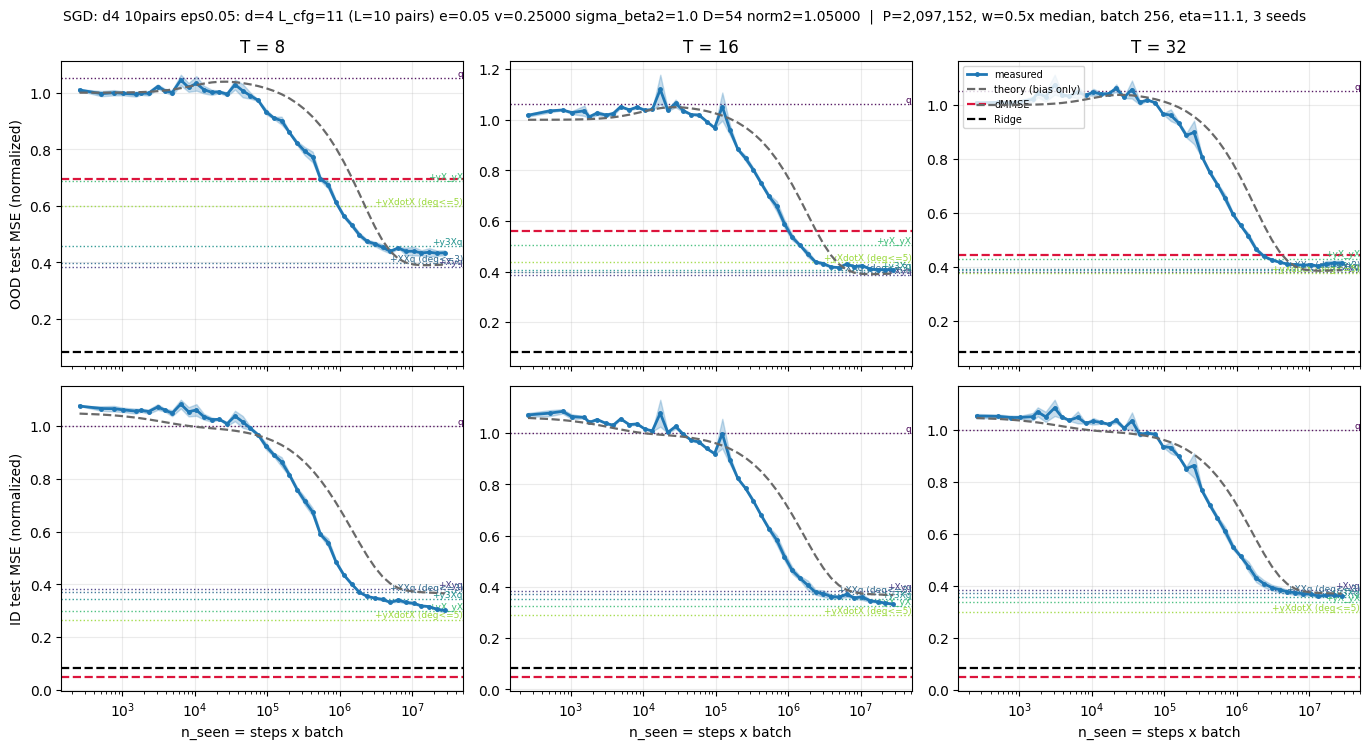

In [ ]:
FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

TU.plot_n_curves(records, CFG, CURVE_TS, markers=None, xlabel="n_seen = steps x batch",
                 title=f"SGD: {CFG.describe()}  |  P={P_FEATURES:,}, w={WIDTH_FACTOR}x median, "
                       f"batch {BATCH}, eta={ETA:.1f}, {TRIALS} seeds",
                 save=os.path.join(FIGDIR, f"rf_transience_sgd_n_{TAG}.pdf"))
plt.show()

## Verdict

Per run: the curve's minimum after the degree-1 stage; the dip, how far that minimum sits below
**both** dMMSE and the null predictor (OOD error 1.0 -- at T=4 the memorizer is worse than predicting
nothing, so beating dMMSE alone would be too easy); and the rise, how far the curve has climbed back
by the end. Each comes with a z-score against the test-set Monte-Carlo error and the theory's numbers
for the same pool. T=8 is the clean version of the story: the untrained model starts above dMMSE
there, dips below it, and climbs back.

In [ ]:
# Measure the dip only after the degree-1 stage: the untrained model predicts 0 (OOD error 1.0), which
# at T=4 is already below dMMSE, so the minimum must come from the trained curve.
N_FROM = SPEC.steps_for("q", ETA, 0.9) * BATCH
VERDICT = TU.transience_verdict(records, T_LIST, side="ood", n_from=N_FROM,
                                require_rise=(TARGET_FAMILY != "XX"))

OOD: dip = min(dMMSE, null=1) - min, rise = end - min, over n >= 16,173;  [theory for the same pool]

T = 8
  trial 0: dMMSE 0.682  min 0.416 at n=17,210,368  end 0.422  | dip +0.266 (z=27)  rise +0.006 (z=1)  | [theory: min 0.392, end 0.394, dip +0.290, rise +0.002]
  trial 1: dMMSE 0.708  min 0.446 at n=22,032,640  end 0.447  | dip +0.262 (z=23)  rise +0.000 (z=0)  | [theory: min 0.389, end 0.391, dip +0.319, rise +0.002]
  mean over 2: dip +0.264 +/- 0.002   rise +0.003 +/- 0.002

T = 16
  trial 0: dMMSE 0.563  min 0.402 at n=22,032,640  end 0.404  | dip +0.160 (z=16)  rise +0.001 (z=0)  | [theory: min 0.394, end 0.398, dip +0.169, rise +0.004]
  trial 1: dMMSE 0.557  min 0.411 at n=28,206,336  end 0.411  | dip +0.146 (z=15)  rise +0.000 (z=0)  | [theory: min 0.385, end 0.385, dip +0.172, rise +0.000]
  mean over 2: dip +0.153 +/- 0.005   rise +0.001 +/- 0.001

T = 32
  trial 0: dMMSE 0.444  min 0.395 at n=17,210,368  end 0.401  | dip +0.049 (z=5)  rise +0.007 (z=1)  | [theory: min 

## Reference: other settings

Everything below is off the focused path. To run another setting, change `DIM, PAIRS, EPS`, `T_LIST`
and `TRIALS` in the configuration cell; P, the step budget and the markers follow automatically and
every checkpoint is keyed on the setting. Keep `PAIRS >= DIM`: with fewer pairs than dimensions,
d - L directions of an OOD task are invisible to *any* in-context learner, so the dip grows only because
every method gets worse.

Predicted OOD dip (dMMSE - floor3) and rise (kappa_3 floor - floor3), eps^2 = 0.05, and SGD cost at
0.5x median for T = 4, 8, 16 (spectrum estimates on an A100; the timing cell measures the real rate):

| DIM, PAIRS | T=8 dip / rise | TARGET_L = 0.9 | TARGET_L = 0.75 (~70% of the rise) |
|---|---|---|---|
| 4, 4 | +0.30 / +0.18 | P=2^19, **~0.5 h** | P=2^18, ~0.2 h |
| 4, 5 | +0.28 / +0.20 | P=2^21, ~5.5 h | P=2^20, **~1.6 h** |
| 4, 6 | +0.29 / +0.21 | P=2^22, ~24 h | P=2^21, ~7 h |
| 5, 5 | +0.37 / +0.20 | P=2^22, ~22 h | P=2^21, ~7 h |
| 5, 6 | +0.38 / +0.22 | ~100 h | ~30 h |
| 6, 6 | +0.50 / +0.25 | ~360 h | ~110 h |

**Why 0.5x median, and what it costs.** Gradient descent needs ~lambda_1/lambda steps for a mode, and
narrowing the kernel is what brings that down: for the kappa_3 family at 4 pairs, lambda_1/lambda is
~2e5 at 0.5x (about 7x the ~27k modes above it) against ~4e9 at 1.5x. The price is that 0.5x is past
where the dot-product (HEA) expansion is accurate -- the per-coordinate eigenvalue ratio for y is 0.19,
not the 0.29 that expansion gives -- so `ChannelSpectrum` uses the exact Mehler form, which matches the
kernel's empirical spectrum on these contexts to ~10-20% over the top ~400 modes. The ordering of the
channels survives; what becomes approximate are the ladder floors, because the eigenfunctions carry a
radial envelope (log-std ~0.35 over the data at 0.5x, ~0.05 at 1.5x) and so are not pure polynomials.
How far the floors shift at this width is not yet quantified; the check is a second width (0.55-0.6x):
if the plateau and the rise land in the same place, the envelope is not moving them.
`WIDTH_FACTOR = 0.45` roughly halves the steps again, with a larger envelope.

**P decides whether the rise appears.** SGD only learns what the features span, and a memorizing
channel's OOD cost grows like its learnability squared (its best OOD coefficient is ~0, so learning it
to L adds ~(L x its training coefficient)^2). `P_FEATURES = "auto"` picks the smallest power of two
that spans the kappa_3 family at `TARGET_L`, capped by GPU memory. The step budget stops at
`min(TARGET_L, what P can hold)`.


### Without whitening (iid task pools): a dip-only run

Set `POOL_KIND = "normal"` (tasks drawn i.i.d. from N(0, I), no whitening) and `TARGET_FAMILY = "XX"`.
With an unwhitened pool the degree-3 channels are learned and the curve dips below dMMSE, but the
predicted curve stays flat at the degree-3 floor for at least 3x the time it takes to learn them -- no
rise within reach -- so the run stops once degree 3 is in, which is far cheaper than training to
kappa_3. Predicted (bias-only theory, eps^2 = 0.05, 0.5x median, mean of 3 pools):

| DIM, PAIRS, T | P | steps (min at) | T4 time per run | dMMSE -> SGD min | dip |
|---|---|---|---|---|---|
| 4, 8, 8 | 2^19 | 65k (~29k) | ~15 min | 0.79 -> 0.60 | +0.18 |
| 5, 10, 8 | 2^21 | 232k (~91k) | ~3.6 h | 0.93 -> 0.68 | +0.25 |
| 6, 9, 8 | 2^21 | 290k (~95k) | ~4.6 h | 0.95 -> 0.68 | +0.26 |
| 8, 8, 16 | 2^22 | 471k (~128k) | ~15 h | 1.05 -> 0.68 | +0.32 |

(An A100 is roughly 5x faster than a T4 on these bandwidth-bound steps. d=8 with 16 pairs -- the paper's
Figure-4 shape -- has the largest dip, +0.40, but needs P ~ 2^25 and ~3.5M steps.) Use T = 8 for
d <= 6 and T = 16 for d = 8; lower noise helps throughout (eps^2 = 0.25 shrinks every dip by ~1/3).

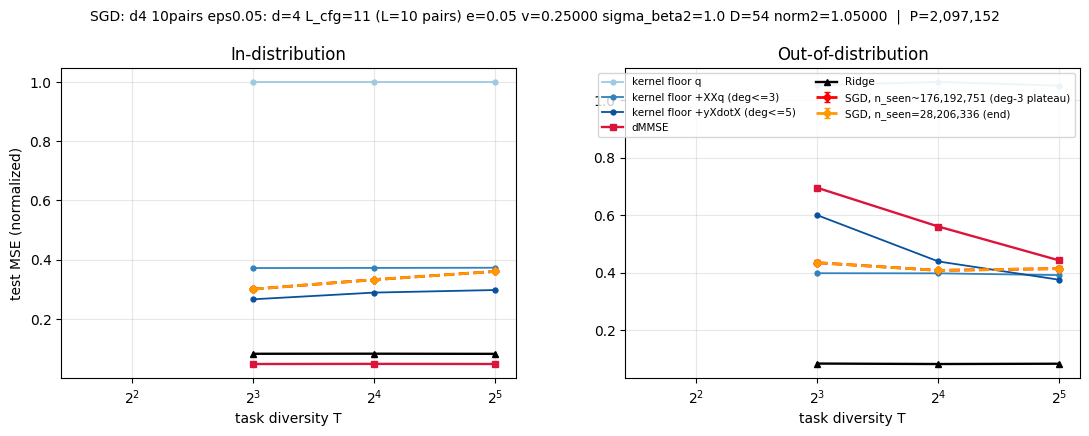

   T   dMMSE  floor3  floor5   Ridge |     min       at n   final | dMMSE-min final-min
   8   0.695   0.398   0.600   0.083 |   0.433 22,032,640   0.434 |    +0.262    +0.001
  16   0.560   0.397   0.439   0.082 |   0.408 28,206,336   0.408 |    +0.153    +0.000
  32   0.442   0.391   0.375   0.083 |   0.402 13,443,328   0.414 |    +0.040    +0.012


In [ ]:
# Figure-4 style error against T -- only meaningful once T_LIST covers a range of T.
if len(T_LIST) >= 3:
    _n_plateau = math.sqrt(SPEC.steps_for("XX", ETA, 0.9) * SPEC.steps_for(K3, ETA, 0.5)) * BATCH
    PICKS = [(f"SGD, n_seen~{_n_plateau:,.0f} (deg-3 plateau)", _n_plateau),
             (f"SGD, n_seen={MAX_STEPS * BATCH:,} (end)", MAX_STEPS * BATCH)]
    TU.plot_T_sweep(records, CFG, T_LIST, PICKS, title=f"SGD: {CFG.describe()}  |  P={P_FEATURES:,}",
                    save=os.path.join(FIGDIR, f"rf_transience_sgd_T_{TAG}.pdf"))
    plt.show()
    TU.summary_table(records, T_LIST)
else:
    print("T-sweep plot skipped: T_LIST has fewer than 3 values.")

## Optional: does early-stopped SGD match the exact ridge solve?

Off by default. On a quadratic, stopping SGD at step t acts like a ridge `1/(eta t)` in covariance
units, so at a size small enough for an exact solve the two curves should overlay when plotted
against that effective ridge. If the SGD curve peels away at small ridge, that is SGD gradient
noise, and it bounds how far up the ladder this batch size can go.

In [ ]:
RUN_VALIDATION = False

if RUN_VALIDATION:
    from kernels_can_icl.random_features import RFFKernelRegressor
    P_v, n_v, T_v = (1_024, 4_000, 4) if SMOKE else (8_192, 60_000, 4)
    td, _ = TU.make_pool_distr(CFG, T_v, SEED, POOL_KIND, DEVICE)
    Xtr, ytr = TU.gen_raw(td, CFG, n_v, "pretrain")[:2]
    Xte, yte = TU.gen_raw(td, CFG, 4096, "true")[:2]
    exact = []
    r = RFFKernelRegressor(ridge=1.0, kernel_width=WIDTH, num_features=P_v, chunk=4096, seed=SEED)
    r.accumulate(Xtr, ytr)
    for rel in np.logspace(-3, -8, 11):
        r.ridge = float(rel * n_v)
        r.solve()
        exact.append((rel, TU.nmse(r.predict(Xte), yte, CFG)))
    del r
    m = RFNet(P_v, D_FLAT, WIDTH, SEED, DEVICE)
    eta_v = LR_FRAC * 2.0 / m.top_eigenvalue(Xtr[:2048])
    steps = int(1.0 / (eta_v * 1e-7)) if not SMOKE else 2_000   # down to effective ridge 1e-7
    marks = sorted({int(round(x)) for x in np.logspace(0, math.log10(steps), 30)})
    sgd, k = [], 0
    for s in range(1, steps + 1):
        m.step(*TU.gen_raw(td, CFG, BATCH, "pretrain")[:2], eta_v)
        if k < len(marks) and s == marks[k]:
            sgd.append((1.0 / (eta_v * s), TU.nmse(m.predict(Xte), yte, CFG)))
            k += 1
    fig, ax = plt.subplots(figsize=(6.2, 4.2))
    ax.plot(*zip(*exact), "o-", label="exact solve (ridge / n)")
    ax.plot(*zip(*sgd), "s--", label="SGD (1 / (eta t))")
    ax.set_xscale("log"); ax.invert_xaxis()
    ax.set_xlabel("effective ridge (covariance units)   more training ->")
    ax.set_ylabel("OOD test MSE (normalized)")
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()

KeyboardInterrupt: 